<a href="https://colab.research.google.com/github/jsherwood2/IS-4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Add code here 🔧
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv')
df.info()
display(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. I noticed that some customers have negative incomes (-$65,600) and  ages up to 132 years old, which are definitely errors or outliers. Also, one person has 3,345 accounts, and there are 2 missing values in 'new_car' and 3 duplicate rows overall.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# Add code here 🔧
df_clean = df[(df['income'] >= 0) & (df['age'] < 100)].copy()
df_clean['new_car'] = df_clean['new_car'].fillna(df_clean['new_car'].mode()[0])
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop(columns=['customer_id', 'product'])

### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed values where income was negative and age was over 100 because they're clearly impossible data errors. I filled the couple of missing new_car values with the most common value (mode) since it's a binary yes/no question and mode is simple.

2.6 I dropped customer_id because it's just a random ID number that doesn't help predict anything, and product because we only find out what product they bought after they already answer the call.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [5]:
# Add code here 🔧
df_clean['answered'] = df_clean['answered'].astype(bool)
df_clean['new_car'] = df_clean['new_car'].astype(int)

## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [13]:
# Add code here 🔧
df_clean['female'] = df_clean['female'].astype('category')
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')

# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



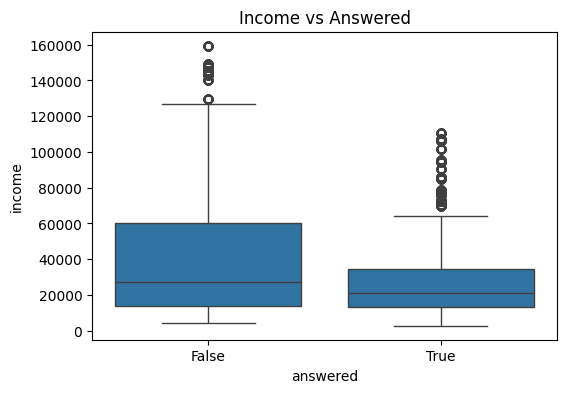

In [8]:
# Chart 3.1 🔧
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income vs Answered')
plt.show()

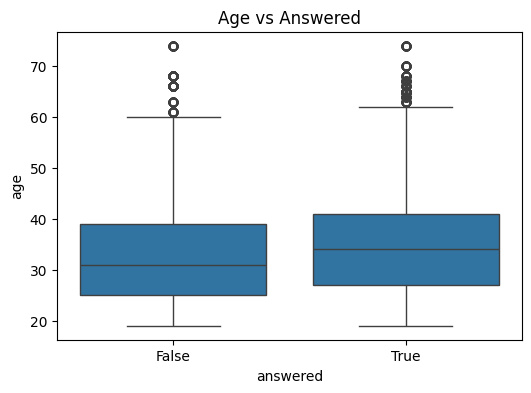

In [9]:
# Chart 3.2 🔧
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_clean, x='answered', y='age')
plt.title('Age vs Answered')
plt.show()

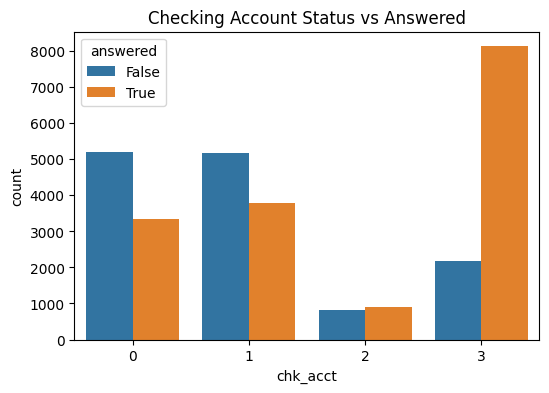

In [10]:
# Chart 3.3 🔧
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='chk_acct', hue='answered')
plt.title('Checking Account Status vs Answered')
plt.show()

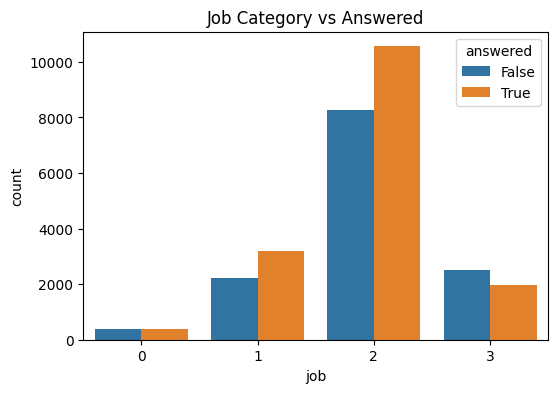

In [11]:
# Chart 3.4 🔧
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='job', hue='answered')
plt.title('Job Category vs Answered')
plt.show()

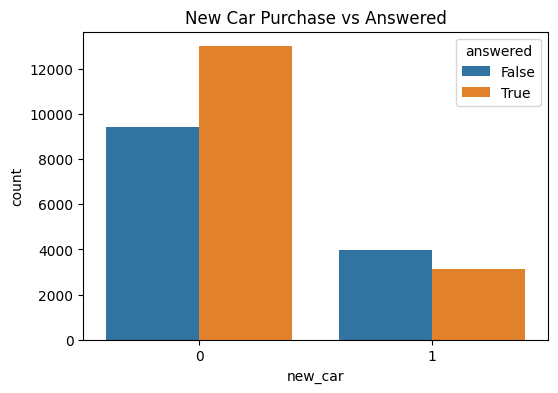

In [12]:
# Chart 3.5 🔧
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='new_car', hue='answered')
plt.title('New Car Purchase vs Answered')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Income and checking account status seem to have the strongest relationships. People who answer have visibly higher median incomes, and those with higher checking account balances are much more likely to pick up the phone.

3.7. Job and whether they bought a new car look pretty weak and don't seem to make a big difference in who answers. I'd keep them for now because a machine learning model might still find small patterns.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [14]:
# Add code here 🔧
base_prob = df_clean['answered'].mean()
print(base_prob)

0.5467150315275612


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [15]:
# Add code here 🔧
X = df_clean.drop(columns=['answered'])
X = pd.get_dummies(X, drop_first=True)
y = df_clean['answered']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

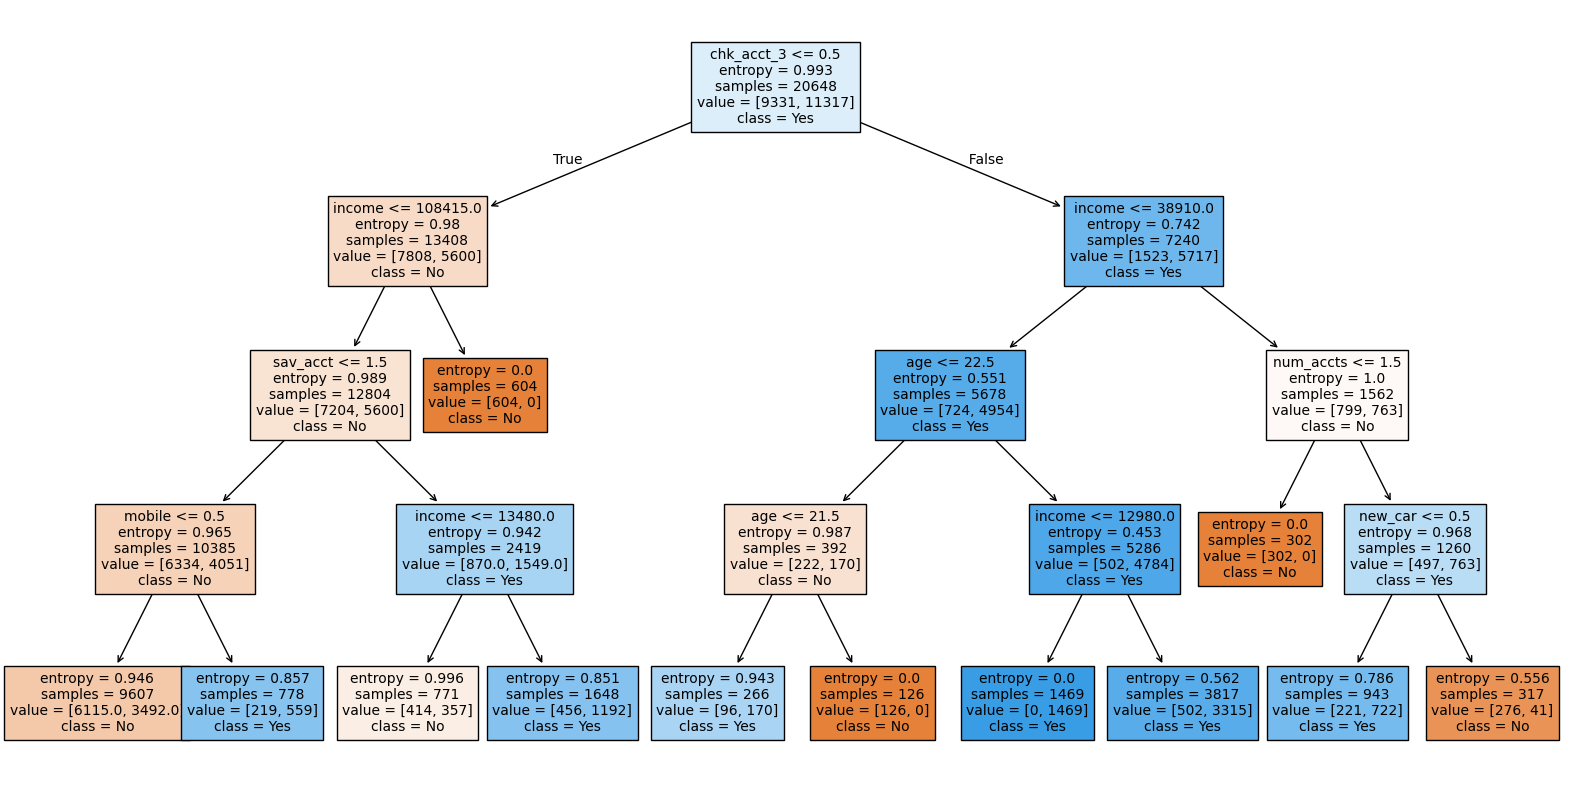

In [16]:
# Add code here 🔧
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
plt.figure(figsize=(20, 10))
plot_tree(dt_model, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [17]:
# Add code here 🔧
y_pred = dt_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred)
print(tree_accuracy)

0.7405649717514124


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model's accuracy is around 74%, which is about 20% higher than the baseline probability of around 54%. That's a huge improvement!

2. Yeah, this difference is super significant for the business. Instead of calling everyone randomly, we can focus our sales team on the people who are actually likely to answer and save a lot of wasted time.

## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [18]:
# Add code here 🔧
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[3422  618]
 [1678 3132]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

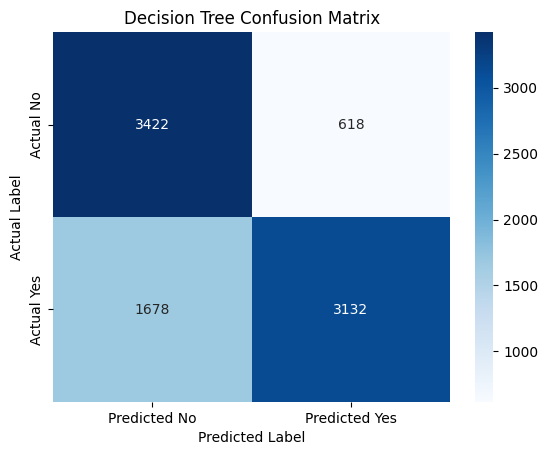

In [19]:
# Add code here 🔧
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted No', 'Predicted Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title('Decision Tree Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [ ]:
# Add code here 🔧

### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1.
2.
3.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
# Add code here 🔧

## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
# Add code here 🔧

### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1.

2.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [ ]:
# Add code here 🔧

## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

In [ ]:
# Add code here 🔧

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1.
2.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

In [ ]:
# Add code here 🔧

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1.
2.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [ ]:
# Example structure; replace the values with your own calculations
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

In [ ]:
# Add code here 🔧

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [ ]:
# Add code here 🔧

### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1.
 2.
 3.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1

6.2

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"